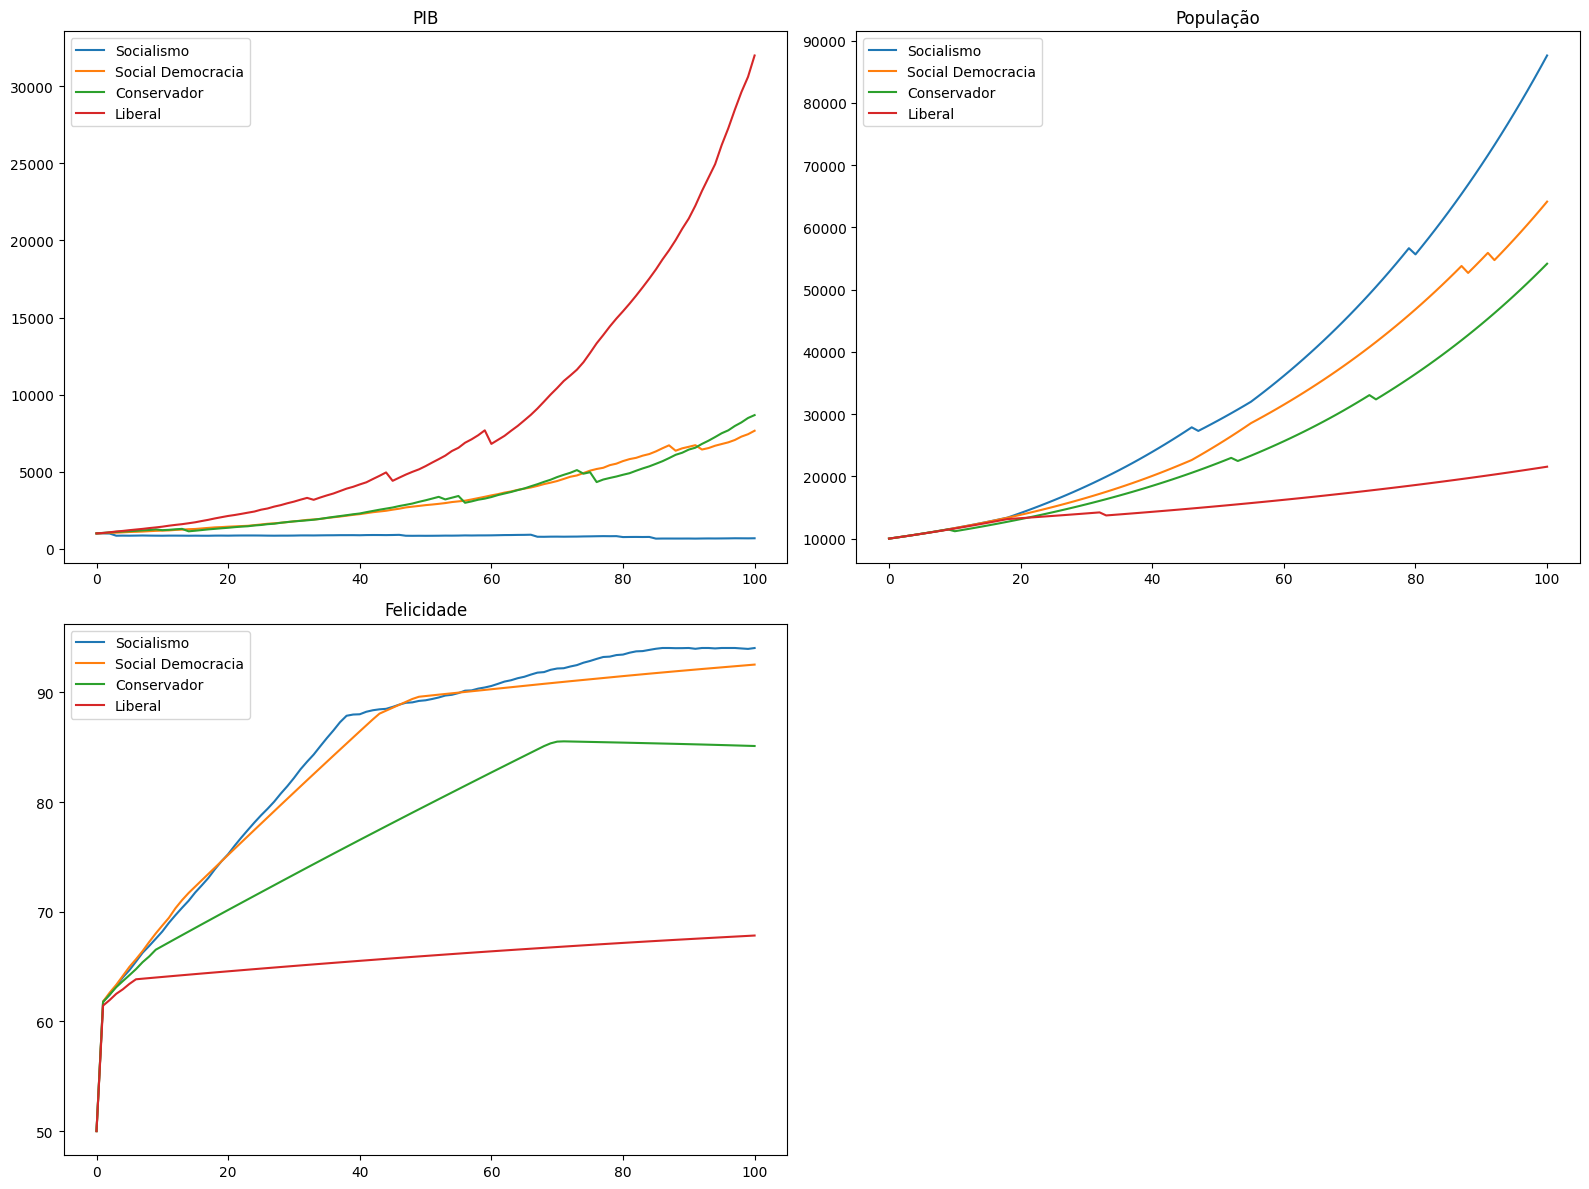


RANKING FINAL



,Modelo,População,PIB,PIB per Capita,Felicidade,Educação,Saúde,Desemprego,Gini,Imigrantes,Emigrantes,Score
0,Socialismo,87605,684.88,0.01,94.04,100.00,100.00,2.01,0.20,12312,0,71.31
1,Social Democracia,64132,7659.71,0.12,92.53,100.00,100.00,2.00,0.26,1386,0,70.40
2,Conservador,54159,8673.88,0.16,85.11,100.00,100.00,2.00,0.53,0,0,65.78
3,Liberal,21552,31998.73,1.48,67.83,78.58,77.95,2.00,0.81,0,13698,52.47


In [6]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import random

random.seed(42)

# =====================================================
# CLASSE ILHA
# =====================================================

class Ilha:

    def __init__(
        self,
        nome,
        populacao,
        recursos,
        imposto,
        liberdade_economica,
        gasto_social,
        investimento_publico
    ):

        self.nome = nome

        self.populacao = float(populacao)
        self.recursos = float(recursos)

        self.imposto = imposto
        self.liberdade_economica = liberdade_economica
        self.gasto_social = gasto_social
        self.investimento_publico = investimento_publico

        self.pib = 1000.0
        self.divida = 0.0

        self.educacao = 50.0
        self.saude = 50.0
        self.inovacao = 50.0

        self.desemprego = 10.0
        self.criminalidade = 20.0

        self.gini = 0.50
        self.felicidade = 50.0

        self.inflacao = 4.0
        self.aprovacao = 50.0

        self.imigrantes = 0
        self.emigrantes = 0

        self.taxa_natalidade = 0.018
        self.taxa_mortalidade = 0.008

    # =========================================

    def atualizar(self):

        produtividade = (
            self.educacao * 0.003 +
            self.inovacao * 0.004
        )

        crescimento = (
            produtividade +
            self.liberdade_economica * 4 -
            self.imposto * 2
        ) / 100

        crescimento += random.uniform(-0.01, 0.01)

        self.pib *= (
            1 + crescimento
        )

        # ARRECADAÇÃO

        arrecadacao = (
            self.pib * self.imposto
        )

        gasto_total = arrecadacao * (
            self.gasto_social +
            self.investimento_publico
        )

        saldo = arrecadacao - gasto_total

        if saldo < 0:
            self.divida += abs(saldo)

        # EDUCAÇÃO

        self.educacao += (
            self.investimento_publico * 1.5
        )

        self.educacao = min(
            100,
            self.educacao
        )

        # SAÚDE

        self.saude += (
            self.gasto_social * 1.5
        )

        self.saude = min(
            100,
            self.saude
        )

        # INOVAÇÃO

        self.inovacao += (
            self.educacao * 0.01
        )

        self.inovacao = min(
            100,
            self.inovacao
        )

        # NATALIDADE

        natalidade_real = (
            self.taxa_natalidade
            + self.saude / 10000
            - self.educacao / 20000
        )

        natalidade_real = max(
            0.003,
            natalidade_real
        )

        nascimentos = (
            self.populacao *
            natalidade_real
        )

        # MORTALIDADE

        mortalidade_real = (
            self.taxa_mortalidade
            - self.saude / 20000
        )

        mortalidade_real = max(
            0.002,
            mortalidade_real
        )

        mortes = (
            self.populacao *
            mortalidade_real
        )

        self.populacao += (
            nascimentos - mortes
        )

        # DESEMPREGO

        self.desemprego -= (
            crescimento * 35
        )

        self.desemprego = max(
            2,
            min(35, self.desemprego)
        )

        # GINI

        self.gini += (
            0.005 -
            self.gasto_social * 0.01
        )

        self.gini = max(
            0.20,
            min(0.90, self.gini)
        )

        # CRIMINALIDADE

        self.criminalidade = (
            self.desemprego * 0.7 +
            self.gini * 45
        )

        self.criminalidade = min(
            100,
            self.criminalidade
        )

        # INFLAÇÃO

        self.inflacao += random.uniform(
            -0.3,
            0.3
        )

        self.inflacao = max(
            0,
            min(20, self.inflacao)
        )

        # RECURSOS

        consumo = (
            self.populacao * 0.05
        )

        self.recursos -= consumo

        self.recursos = max(
            0,
            self.recursos
        )

        # FELICIDADE

        self.felicidade = (

            self.saude * 0.25 +

            self.educacao * 0.20 +

            (100 - self.desemprego) * 0.20 +

            (100 - self.criminalidade) * 0.15 +

            (100 - self.gini * 100) * 0.20

        )

        self.felicidade = max(
            0,
            min(100, self.felicidade)
        )

        # APROVAÇÃO

        self.aprovacao = (

            self.felicidade * 0.40 +

            (100 - self.desemprego) * 0.30 +

            (100 - self.criminalidade) * 0.20 +

            (100 - self.inflacao * 5) * 0.10

        )

        self.aprovacao = max(
            0,
            min(100, self.aprovacao)
        )

        self.eventos()

    # =========================================

    def eleicao(self):

        if self.aprovacao < 50:

            escolha = random.choice(
                ["social", "economico"]
            )

            if escolha == "social":

                self.gasto_social *= 1.05

            else:

                self.investimento_publico *= 1.05

        else:

            if random.random() < 0.5:

                self.gasto_social *= 0.99

            else:

                self.investimento_publico *= 0.99

        self.gasto_social = min(
            self.gasto_social,
            1.2
        )

        self.investimento_publico = min(
            self.investimento_publico,
            1.2
        )

    # =========================================

    def eventos(self):

        r = random.random()

        if r < 0.02:

            self.populacao *= 0.96
            self.pib *= 0.93

        elif r < 0.04:

            self.recursos *= 0.85

        elif r < 0.06:

            self.recursos *= 1.20

        elif r < 0.08:

            self.inovacao += 10

        elif r < 0.10:

            self.pib *= 0.85


# =====================================================
# MIGRAÇÃO
# =====================================================

def migracao(ilhas):

    melhor = max(
        ilhas,
        key=lambda x: x.felicidade
    )

    pior = min(
        ilhas,
        key=lambda x: x.felicidade
    )

    diferenca = (
        melhor.felicidade -
        pior.felicidade
    )

    if diferenca > 10:

        migrantes = int(
            pior.populacao * 0.01
        )

        pior.populacao -= migrantes
        melhor.populacao += migrantes

        pior.emigrantes += migrantes
        melhor.imigrantes += migrantes


# =====================================================
# REGIMES
# =====================================================

ilhas = [

    Ilha(
        "Socialismo",
        10000,
        200000,
        0.60,
        0.20,
        0.90,
        0.90
    ),

    Ilha(
        "Social Democracia",
        10000,
        200000,
        0.40,
        0.60,
        0.80,
        0.70
    ),

    Ilha(
        "Conservador",
        10000,
        200000,
        0.30,
        0.70,
        0.50,
        0.50
    ),

    Ilha(
        "Liberal",
        10000,
        200000,
        0.15,
        0.95,
        0.20,
        0.20
    )

]

# =====================================================
# SIMULAÇÃO
# =====================================================

historico = []

for ano in range(101):

    if ano > 0:

        for ilha in ilhas:
            ilha.atualizar()

        migracao(ilhas)

        if ano % 4 == 0:

            for ilha in ilhas:
                ilha.eleicao()

    linha = {"Ano": ano}

    for ilha in ilhas:

        linha[f"PIB_{ilha.nome}"] = ilha.pib
        linha[f"POP_{ilha.nome}"] = ilha.populacao
        linha[f"FEL_{ilha.nome}"] = ilha.felicidade

    historico.append(linha)

df = pd.DataFrame(historico)

# =====================================================
# GRÁFICOS
# =====================================================

fig, axs = plt.subplots(2,2, figsize=(16,12))

for ilha in ilhas:
    axs[0,0].plot(
        df["Ano"],
        df[f"PIB_{ilha.nome}"],
        label=ilha.nome
    )

axs[0,0].set_title("PIB")
axs[0,0].legend()

for ilha in ilhas:
    axs[0,1].plot(
        df["Ano"],
        df[f"POP_{ilha.nome}"],
        label=ilha.nome
    )

axs[0,1].set_title("População")
axs[0,1].legend()

for ilha in ilhas:
    axs[1,0].plot(
        df["Ano"],
        df[f"FEL_{ilha.nome}"],
        label=ilha.nome
    )

axs[1,0].set_title("Felicidade")
axs[1,0].legend()

axs[1,1].axis("off")

plt.tight_layout()
plt.show()

# =====================================================
# RESULTADO FINAL
# =====================================================

resultado = []

for ilha in ilhas:

    pib_per_capita = (
        ilha.pib /
        ilha.populacao
    )

    score = (

        pib_per_capita * 0.25 +

        ilha.felicidade * 0.25 +

        ilha.educacao * 0.15 +

        ilha.saude * 0.15 +

        (100 - ilha.gini * 100) * 0.10 +

        (100 - ilha.desemprego) * 0.10

    )

    resultado.append({

        "Modelo": ilha.nome,
        "População": int(ilha.populacao),
        "PIB": round(ilha.pib,2),
        "PIB per Capita": round(pib_per_capita,2),
        "Felicidade": round(ilha.felicidade,2),
        "Educação": round(ilha.educacao,2),
        "Saúde": round(ilha.saude,2),
        "Desemprego": round(ilha.desemprego,2),
        "Gini": round(ilha.gini,2),
        "Imigrantes": ilha.imigrantes,
        "Emigrantes": ilha.emigrantes,
        "Score": round(score,2)

    })

resultado = pd.DataFrame(resultado)

print("\nRANKING FINAL\n")

display(
    resultado.sort_values(
        by="Score",
        ascending=False
    )
)